# Replicating Hannachi (2004), *A primer for EOF analysis of climate data*, Sections 1–3

This notebook works through the paper's method one equation at a time, using NOAA monthly NetCDF data. Then it reproduces the paper's worked example (Section 3.5): **EOFs of winter (DJF) monthly sea level pressure (SLP) over the Northern Hemisphere north of 20°N**.

The notebook is self-contained. All of `eofkit/eof.py` is reproduced below, split across the cells for the equations it implements, together with the few data-loading and plotting helpers it needs. Nothing is imported from `eofkit`.

| Paper | What this notebook does |
|---|---|
| §2.1, eqs. (1)–(2) | Load the NetCDF field $F(t,\phi,\lambda)$ and reshape it to the data matrix $X$ ($n \times p$) |
| §2.1, eqs. (3)–(4) | Remove the seasonal cycle to get the anomalies $X'$ |
| §2.2, eqs. (5)–(6) | Area weighting $X'_w = X' D$ |
| §3.1–3.2, eqs. (7)–(10) | Covariance matrix, EOFs as its eigenvectors, PCs as projections |
| §3.3, eq. (13) | Compute everything with the SVD of $X'_w$ |
| §3.3, eq. (12) | North et al. (1982) error bars and separability of eigenvalues |
| §3.4, eq. (11) | Truncation and reconstruction |
| §3.5 | **Figures 1–3** of the paper, and its quoted 21% and 13% explained variances |

There are two runs:

- **Run A, paper period.** Every DJF month from January 1948 to December 2000, the paper's own sample. This run checks the code against the paper.
- **Run B, project window.** The last 30 complete winters in the file, December 1996 to February 2026.

**Data.** NCEP/NCAR Reanalysis 1 monthly mean SLP, 2.5° grid, from NOAA PSL (`slp.mon.mean.nc`). The full download in `data/` is used if present; otherwise the compact Northern Hemisphere copy in `data/compact/`. Both give identical results. The NOAA CPC monthly AO index is used only to validate PC1.

## 0. Setup

In [1]:
from __future__ import annotations

from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.path as mpath
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from IPython.display import display

%matplotlib inline
pd.set_option("display.precision", 3)

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
COMPACT_DIR = DATA_DIR / "compact"
print("numpy", np.__version__, "| xarray", xr.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | xarray 2026.9.0 | matplotlib 3.11.2


Plot style and colours, the same as in the project's figures. Blue and orange mark PC1 and PC2. Signed fields use a diverging blue–grey–red scale.

In [2]:
SURFACE = "#fcfcfb"


INK = "#0b0b0b"


INK_2 = "#52514e"


MUTED = "#898781"


GRID = "#e1e0d9"


AXIS = "#c3c2b7"


BLUE = "#2a78d6"


ORANGE = "#eb6834"


RED = "#d03b3b"


DIV_COLORS = ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
              "#f8d3cf", "#f09b93", "#e34948", "#b8302f", "#7a1a1a"]


CMAP_DIV = LinearSegmentedColormap.from_list("blue_grey_red", DIV_COLORS)


PC_COLORS = [BLUE, ORANGE]


def set_style() -> None:
    matplotlib.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
        "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
        "axes.titlelocation": "left", "axes.titlepad": 8,
        "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
        "axes.spines.top": False, "axes.spines.right": False,
        "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
        "lines.linewidth": 1.6,
    })


set_style()

## 1. Section 2.1: loading the data

The NOAA PSL monthly-mean files store `slp(time, lat, lon)`, with longitude from 0 to 360 and latitude running from 90 down to −90. On load, latitude is sorted ascending and the units are normalised to hPa. A DJF winter is labelled by the year of its January and February, so December 1996 belongs to winter 1997.

In [3]:
def data_file(name: str) -> Path:
    """The full download in data/ if present, else the compact copy in
    data/compact/ (see scripts/make_compact_data.py). Returns the data/ path
    when neither exists, so error messages point to the download location."""
    full = DATA_DIR / name
    if full.exists():
        return full
    compact = COMPACT_DIR / name
    return compact if compact.exists() else full


DATASETS = {
    "slp": dict(
        file="slp.mon.mean.nc", var="slp", label="Sea level pressure", units="hPa",
        source="NCEP/NCAR Reanalysis 1 (monthly means, 2.5°)",
        url="https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/surface/slp.mon.mean.nc",
    ),
    "air": dict(
        file="air.mon.mean.nc", var="air", label="Surface air temperature", units="°C",
        source="NCEP/NCAR Reanalysis 1 (monthly means, 2.5°, sigma 0.995)",
        url="https://downloads.psl.noaa.gov/Datasets/ncep.reanalysis.derived/surface/air.mon.mean.nc",
    ),
    "precip": dict(
        file="precip.mon.mean.nc", var="precip", label="Precipitation", units="mm/day",
        source="GPCP v2.3 (monthly means, 2.5°)",
        url="https://downloads.psl.noaa.gov/Datasets/gpcp/precip.mon.mean.nc",
    ),
}


SEASONS = {
    "DJF": (12, 1, 2),
    "MAM": (3, 4, 5),
    "JJA": (6, 7, 8),
    "SON": (9, 10, 11),
    "Annual": tuple(range(1, 13)),
}


REGIONS = {
    "NH north of 20N (paper)": dict(lat=(20.0, 90.0), lon=(0.0, 360.0)),
    "Northern Hemisphere": dict(lat=(0.0, 90.0), lon=(0.0, 360.0)),
    "Global": dict(lat=(-90.0, 90.0), lon=(0.0, 360.0)),
    "North Atlantic / Europe": dict(lat=(20.0, 80.0), lon=(-90.0, 40.0)),
    "Pakistan-centred (10-50N, 40-100E)": dict(lat=(10.0, 50.0), lon=(40.0, 100.0)),
    "Tropical Pacific": dict(lat=(-30.0, 30.0), lon=(120.0, 290.0)),
}


def open_field(key: str, data_dir: Path | str | None = None) -> xr.DataArray:
    """Open one dataset as a DataArray with dims (time, lat, lon), lat ascending.

    Units are normalised to those listed in DATASETS (hPa, °C, mm/day).
    Without data_dir, the full file in data/ is used if present, otherwise the
    compact regional copy in data/compact/.
    """
    meta = DATASETS[key]
    path = data_file(meta["file"]) if data_dir is None else Path(data_dir) / meta["file"]
    data_dir = path.parent
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Run  python scripts/download_data.py  first "
            f"(or download {meta['url']} into {data_dir})."
        )
    # The bounds variables are not needed, and GPCP's time_bnds contains fill
    # values that cannot be decoded as dates, so drop them on read.
    ds = xr.open_dataset(path, drop_variables=["time_bnds", "lat_bnds", "lon_bnds", "climatology_bounds"])
    da = ds[meta["var"]]
    if "latitude" in da.dims:
        da = da.rename({"latitude": "lat", "longitude": "lon"})
    da = da.squeeze(drop=True)

    units = str(da.attrs.get("units", "")).lower()
    if key == "air" and (units.startswith("k") or float(da.isel(time=0).mean()) > 150.0):
        da = da - 273.15
    if key == "slp" and units in ("pa", "pascals"):
        da = da / 100.0

    if float(da.lat[0]) > float(da.lat[-1]):
        da = da.sortby("lat")

    da.attrs.update(key=key, label=meta["label"], units=meta["units"], source=meta["source"])
    return da


def select_region(da: xr.DataArray, lat=(-90.0, 90.0), lon=(0.0, 360.0)) -> xr.DataArray:
    """Subset to a lat/lon box. Longitudes may be given in -180..180 or 0..360
    and may wrap across the date line (e.g. lon=(-90, 40))."""
    la0, la1 = lat
    da = da.sel(lat=da.lat[(da.lat >= la0) & (da.lat <= la1)])
    lo0, lo1 = lon
    if lo1 - lo0 >= 360.0:
        return da
    lonv = da.lon.values % 360.0
    lo0m, lo1m = lo0 % 360.0, lo1 % 360.0
    if lo0m <= lo1m:
        mask = (lonv >= lo0m) & (lonv <= lo1m)
    else:
        mask = (lonv >= lo0m) | (lonv <= lo1m)
    return da.isel(lon=np.where(mask)[0])


def season_year(time, months) -> np.ndarray:
    """Season label for each time step. For a wrap-around season such as DJF,
    December belongs to the *following* year's season (Dec 1996 -> winter 1997)."""
    t = pd.DatetimeIndex(time)
    yr = t.year.values.copy()
    if 12 in months and 1 in months:
        yr[t.month.values == 12] += 1
    return yr


def _season_complete(da: xr.DataArray, year: int, months) -> bool:
    t = pd.DatetimeIndex(da.time.values)
    have = set(zip(t.year.values.tolist(), t.month.values.tolist()))
    wrap = 12 in months and 1 in months
    for m in months:
        y = year - 1 if (wrap and m == 12) else year
        if (y, m) not in have:
            return False
    return True


def latest_complete_season_year(da: xr.DataArray, months) -> int:
    t_last = pd.Timestamp(da.time.values[-1])
    y = t_last.year + (1 if (12 in months and 1 in months and t_last.month == 12) else 0)
    while y > 1800 and not _season_complete(da, y, months):
        y -= 1
    return y


def default_years(da: xr.DataArray, months, n_years: int = 30) -> tuple[int, int]:
    """The professor's rule: the last `n_years` complete seasons in the file."""
    y_end = latest_complete_season_year(da, months)
    return y_end - n_years + 1, y_end


def season_time_range(year_start: int, year_end: int, months):
    wrap = 12 in months and 1 in months
    if wrap:
        start = pd.Timestamp(year=year_start - 1, month=12, day=1)
        last_m = max(m for m in months if m < 12)
        end = pd.Timestamp(year=year_end, month=last_m, day=1) + pd.offsets.MonthEnd(0)
    else:
        start = pd.Timestamp(year=year_start, month=min(months), day=1)
        end = pd.Timestamp(year=year_end, month=max(months), day=1) + pd.offsets.MonthEnd(0)
    return start, end


def select_season(da: xr.DataArray, months, year_start: int, year_end: int) -> xr.DataArray:
    """Keep only the months of one season between two season-years (inclusive)
    and attach a `season_year` coordinate."""
    start, end = season_time_range(year_start, year_end, months)
    da = da.sel(time=slice(start, end))
    da = da.sel(time=da.time.dt.month.isin(list(months)))
    return da.assign_coords(season_year=("time", season_year(da.time.values, months)))

In [4]:
slp = open_field("slp")
print(slp.attrs["source"])
print(f"file: {data_file(DATASETS['slp']['file'])}")
print(f"{slp.sizes['time']} months, {slp.time.values[0]:.10} to {slp.time.values[-1]:.10}")
print(f"grid {slp.sizes['lat']} x {slp.sizes['lon']} (lat {float(slp.lat.min())} to {float(slp.lat.max())})")
slp

NCEP/NCAR Reanalysis 1 (monthly means, 2.5°)
file: /Users/a.jogiat/Desktop/code/pakistan-winters-eof/data/compact/slp.mon.mean.nc
938 months, 1948-01-01 to 2026-02-01
grid 37 x 144 (lat 0.0 to 90.0)


<xarray.DataArray 'slp' (time: 938, lat: 37, lon: 144)> Size: 20MB
[4997664 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 8kB 1948-01-01 1948-02-01 ... 2026-02-01
  * lat      (lat) float32 148B 0.0 2.5 5.0 7.5 10.0 ... 82.5 85.0 87.5 90.0
  * lon      (lon) float32 576B 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Attributes: (12/13)
    long_name:     Sea Level Pressure
    valid_range:   [ 870. 1150.]
    units:         hPa
    precision:     1
    var_desc:      Sea Level Pressure
    level_desc:    Sea Level
    ...            ...
    parent_stat:   Other
    dataset:       NCEP Reanalysis Derived Products
    actual_range:  [ 955.56085 1082.5582 ]
    key:           slp
    label:         Sea level pressure
    source:        NCEP/NCAR Reanalysis 1 (monthly means, 2.5°)

## 2. Equations (3)–(4): anomalies

The anomaly at each grid point and month subtracts the mean of that calendar month over the analysis window ("monthly averaged values then removed", §3.5):

$$X'(t, s) = X(t, s) - \bar{X}_{m(t)}(s), \qquad \bar{X}_m(s) = \frac{1}{n_m}\sum_{t:\,m(t)=m} X(t,s).$$

This leaves every column of $X'$ with zero time mean, so $\Sigma$ in eq. (7) is a covariance matrix.

In [5]:
def anomalies(da: xr.DataArray) -> tuple[xr.DataArray, xr.DataArray]:
    """Eq. (3)-(4): remove the seasonal cycle, computed as the mean of each
    calendar month over the analysis window ("monthly averaged values then
    removed", paper Sec. 3.5). Returns (anomaly, climatology)."""
    clim = da.groupby("time.month").mean("time")
    anom = (da.groupby("time.month") - clim).drop_vars("month", errors="ignore")
    anom.attrs.update(da.attrs)
    return anom, clim

## 3. Equation (5): area weighting

Grid points crowd together towards the pole, so an unweighted analysis over-counts high latitudes. The paper weights the data with a diagonal matrix $D$:

$$X'_w = X' D, \qquad D = \operatorname{diag}(\cos\phi_1, \dots, \cos\phi_p). \tag{5–6}$$

`area_weights` offers three schemes. With $D = \operatorname{diag}(\sqrt{\cos\phi})$, the covariance $\Sigma = D X'^{T} X' D/(n-1)$ is weighted by $\cos\phi$, which is proportional to grid-cell area. Section 8 below shows that **this** scheme reproduces the paper's quoted numbers, so it is the default.

In [6]:
def area_weights(da: xr.DataArray, scheme: str = "cos") -> xr.DataArray:
    """Eq. (5): the diagonal weighting matrix D as a (lat, lon) field.

    scheme="cos"      D = diag(cos phi)            eq. (5) exactly as printed
    scheme="sqrtcos"  D = diag(sqrt(cos phi))      the covariance (7) is then weighted
                      by cos phi, i.e. by grid-cell area. This is the scheme that
                      reproduces the paper's own numbers (21% / 13% for 1948-2000),
                      so it is the project default.
    scheme="none"     no weighting (shows the polar artefact the paper warns about)
    """
    w_lat = np.cos(np.deg2rad(da.lat.values)).clip(min=0.0)
    if scheme == "sqrtcos":
        w_lat = np.sqrt(w_lat)
    elif scheme == "none":
        w_lat = np.ones_like(w_lat)
    elif scheme != "cos":
        raise ValueError(f"unknown weighting scheme {scheme!r}")
    w2d = np.broadcast_to(w_lat[:, None], (da.lat.size, da.lon.size)).copy()
    return xr.DataArray(w2d, coords={"lat": da.lat, "lon": da.lon}, dims=("lat", "lon"))

## 4. Equations (1)–(2): the data matrix

The field $F(t, \phi, \lambda)$, with $n$ times and a $p_1 \times p_2$ grid, is reshaped so that each row is one map:

$$X = \begin{pmatrix} x_{11} & \cdots & x_{1p} \\ \vdots & & \vdots \\ x_{n1} & \cdots & x_{np}\end{pmatrix}, \qquad p = p_1 p_2.$$

This is the paper's MATLAB `reshape`.

In [7]:
def to_matrix(anom: xr.DataArray) -> tuple[np.ndarray, xr.DataArray]:
    """Eq. (1)-(2): concatenate the two spatial dimensions,
    F (n, p1, p2) -> X (n, p). Equivalent to the paper's MATLAB reshape."""
    stacked = anom.transpose("time", "lat", "lon").stack(space=("lat", "lon"))
    return np.asarray(stacked.values, dtype=float), stacked

### A first look at the matrices

Below, the steps so far run on Run A's sample (every DJF month, 1948–2000, north of 20°N):

F : {'time': 159, 'lat': 29, 'lon': 144}
X': (159, 4176)  (n months x p grid points)
max |time mean of any column of X'| = 8.72e-14 hPa  (eq. 4: centred)


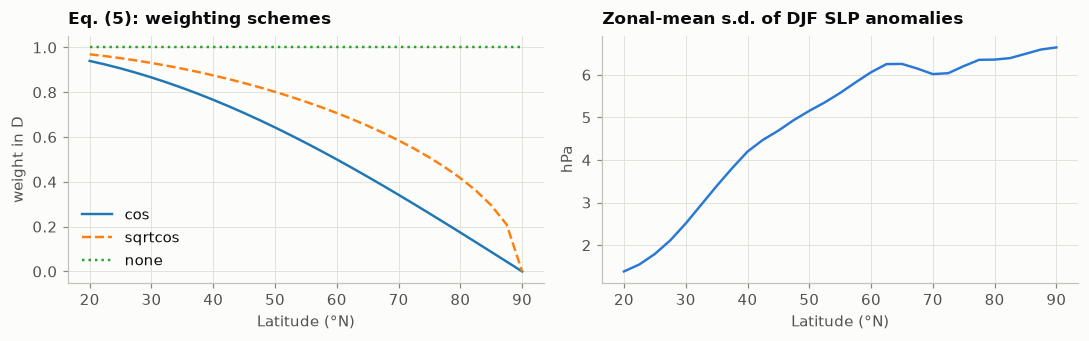

In [8]:
box = REGIONS["NH north of 20N (paper)"]
djf = select_region(slp, **box).sel(time=slice("1948-01", "2000-12"))
djf = djf.sel(time=djf.time.dt.month.isin([12, 1, 2])).load().astype("float64")

anom_demo, clim_demo = anomalies(djf)
X_demo, _ = to_matrix(anom_demo)
print(f"F : {dict(djf.sizes)}")
print(f"X': {X_demo.shape}  (n months x p grid points)")
print(f"max |time mean of any column of X'| = {np.abs(X_demo.mean(axis=0)).max():.2e} hPa  (eq. 4: centred)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for sch, ls in [("cos", "-"), ("sqrtcos", "--"), ("none", ":")]:
    w = area_weights(anom_demo, sch).values[:, 0]
    axes[0].plot(anom_demo.lat, w, ls, label=sch)
axes[0].set_xlabel("Latitude (°N)"); axes[0].set_ylabel("weight in D")
axes[0].set_title("Eq. (5): weighting schemes"); axes[0].legend()
sd = anom_demo.std("time").mean("lon")
axes[1].plot(sd.lat, sd, color=BLUE)
axes[1].set_xlabel("Latitude (°N)"); axes[1].set_ylabel("hPa")
axes[1].set_title("Zonal-mean s.d. of DJF SLP anomalies")
fig.tight_layout(); plt.show()

## 5. Section 3: EOFs by singular value decomposition

The covariance matrix of the weighted anomalies is

$$\Sigma = \frac{1}{n-1} X_w'^{T} X'_w. \tag{7}$$

The EOFs $a_k$ are its eigenvectors, and its eigenvalues $\lambda_k$ give the variance each one explains:

$$\Sigma\, a_k = \lambda_k a_k, \qquad \text{explained variance} = \frac{100\,\lambda_k}{\sum_j \lambda_j}\,\%. \tag{8–9}$$

The principal components are the projections of the data on the EOFs:

$$c_k = X'_w a_k. \tag{10}$$

**Eq. (13).** Here $p = 4176 \gg n$. Instead of forming the $p\times p$ matrix $\Sigma$, we take the thin SVD $X'_w = U S V^T$. The rows of $V^T$ are the EOFs, $\lambda_k = s_k^2/(n-1)$, and $c_k = s_k u_k$. This costs $O(n^2 p)$ instead of $O(p^3)$.

**Eq. (12), North et al. (1982).** The sampling error of an eigenvalue is roughly

$$\delta\lambda_k \approx \lambda_k \sqrt{2/n}.$$

If the error bars of neighbouring eigenvalues overlap, their EOFs are degenerate and can mix. Footnote 2 of the paper notes that $n$ should count *independent* samples. `effective_sample_size` gives that estimate, but the paper uses $n$, and so do we.

In [9]:
def effective_sample_size(x: np.ndarray) -> float:
    """Heuristic effective sample size n (1 - r1) / (1 + r1) from the lag-1
    autocorrelation r1 (paper footnote 2: n should count independent samples)."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    denom = float(np.dot(x, x))
    r1 = float(np.dot(x[:-1], x[1:]) / denom) if denom > 0 else 0.0
    r1 = min(max(r1, -0.99), 0.99)
    return float(x.size * (1.0 - r1) / (1.0 + r1))

`EOFResult` holds every output of one analysis. Its methods carry the rest of Section 3:

- `regression_map` gives the pattern in hPa per standard deviation of the PC, the usual way to draw EOF maps (Fig. 2).
- `reconstruct` and `rmse_curve` give the truncated expansion of eq. (11).
- `separable` applies North's rule.
- `flip_sign` reflects that EOFs are defined only up to sign (§3.4).

In [10]:
@dataclass
class EOFResult:
    """Everything produced by one EOF analysis.

    Spatial arrays are (k, p1, p2) or (p1, p2); time arrays are (n, k) or (n,).
    """
    eofs: np.ndarray            # (k, p1, p2) unit-norm loadings in weighted space (NaN = unused)
    pcs: np.ndarray             # (n, k) raw PCs  c_k = X'_w a_k               eq. (10)
    pcs_std: np.ndarray         # (n, k) standardised PCs (zero mean, unit variance)
    eigvals: np.ndarray         # (k,)  lambda_k
    var_pct: np.ndarray         # (k,)  100 lambda_k / sum lambda
    north_err: np.ndarray       # (k,)  d lambda_k = lambda_k sqrt(2 / n_eff)  eq. (12)
    north_err_pct: np.ndarray   # (k,)  same, in % of total variance
    all_var_pct: np.ndarray     # every non-zero eigenvalue in %, for the spectrum plot
    all_north_err_pct: np.ndarray
    total_var: float
    n: int
    p: int
    p_used: int
    n_eff: float
    time: pd.DatetimeIndex
    season_year: np.ndarray | None
    lat: np.ndarray
    lon: np.ndarray
    weights: np.ndarray         # (p1, p2) the diagonal of D
    valid: np.ndarray           # (p1, p2) bool, columns that entered the SVD
    anom: np.ndarray            # (n, p1, p2) unweighted anomalies (physical units)
    meta: dict = field(default_factory=dict)
    _svd: tuple = field(default=None, repr=False)   # (U, s, Vt) restricted to valid columns

    # ----- spatial patterns ------------------------------------------------------
    def loading_map(self, k: int, unweight: bool = False) -> np.ndarray:
        """The k-th EOF a_k as a map (unit vector in the weighted space).
        unweight=True divides by the weights to show the pattern in the
        original (unweighted) coordinates."""
        pat = self.eofs[k].copy()
        if unweight:
            with np.errstate(divide="ignore", invalid="ignore"):
                pat = np.where(self.weights > 1e-8, pat / self.weights, np.nan)
        return pat

    def regression_map(self, k: int) -> np.ndarray:
        """Anomaly field regressed on standardised PC k: the pattern in physical
        units per one standard deviation of the PC (hPa per s.d. for SLP).
        This is how EOF maps are usually drawn for interpretation."""
        X = self.anom.reshape(self.n, -1)
        c = self.pcs_std[:, k]
        return (X.T @ c / (self.n - 1)).reshape(self.lat.size, self.lon.size)

    # ----- eq. (11): truncated reconstruction --------------------------------------
    def reconstruct(self, k: int, t: int | None = None) -> np.ndarray:
        """Reconstruct the (unweighted) anomaly field from the leading k EOFs.
        Returns (n, p1, p2), or (p1, p2) when a time index t is given."""
        U, s, Vt = self._svd
        rows = slice(None) if t is None else slice(t, t + 1)
        Xw_hat = (U[rows, :k] * s[:k]) @ Vt[:k]                     # eq. (11), weighted space
        vmask = self.valid.reshape(-1)
        w = self.weights.reshape(-1)[vmask]
        out = np.full((Xw_hat.shape[0], self.lat.size * self.lon.size), np.nan)
        out[:, vmask] = Xw_hat / w                                   # undo D
        out = out.reshape(-1, self.lat.size, self.lon.size)
        return out[0] if t is not None else out

    def rmse_curve(self, ks) -> np.ndarray:
        """Area-weighted RMSE (physical units) of the rank-k reconstruction for
        each k in ks, computed over all n time steps."""
        vmask = self.valid.reshape(-1)
        cosw = (np.cos(np.deg2rad(self.lat))[:, None] * np.ones((1, self.lon.size))).reshape(-1)[vmask]
        X = self.anom.reshape(self.n, -1)[:, vmask]
        U, s, Vt = self._svd
        w = self.weights.reshape(-1)[vmask]
        out = []
        for k in ks:
            Xhat = ((U[:, :k] * s[:k]) @ Vt[:k]) / w
            err2 = ((X - Xhat) ** 2 * cosw).sum() / (cosw.sum() * self.n)
            out.append(float(np.sqrt(err2)))
        return np.asarray(out)

    def compression_ratio(self, k: int) -> float:
        """Storage of the full matrix (n p) over storage of the rank-k factors k (n + p)."""
        return (self.n * self.p_used) / (k * (self.n + self.p_used))

    # ----- eq. (12): is EOF k separable from its neighbours? -------------------------
    def separable(self) -> np.ndarray:
        """True when the North error bar of eigenvalue k does not overlap the bars
        of its neighbours k-1 and k+1 (otherwise the EOFs are degenerate / mixed)."""
        lam, err = self.all_var_pct, self.all_north_err_pct
        lo, hi = lam - err, lam + err
        ok = np.ones(lam.size, dtype=bool)
        ok[1:] &= hi[1:] < lo[:-1]
        ok[:-1] &= lo[:-1] > hi[1:]
        return ok[: self.eigvals.size]

    def table(self) -> pd.DataFrame:
        return pd.DataFrame({
            "EOF": np.arange(1, self.eigvals.size + 1),
            "eigenvalue": self.eigvals,
            "variance_%": self.var_pct,
            "cumulative_%": np.cumsum(self.var_pct),
            "north_error_%": self.north_err_pct,
            "separable": self.separable(),
        })

    def flip_sign(self, k: int) -> None:
        """EOFs are defined only up to sign (paper Sec. 3.4). Flip EOF k and its PC."""
        self.eofs[k] *= -1
        self.pcs[:, k] *= -1
        self.pcs_std[:, k] *= -1
        U, s, Vt = self._svd
        U[:, k] *= -1
        Vt[k] *= -1

`compute_eofs` carries out Section 3 itself. Grid columns with missing values or zero weight are left out; the pole row has $\cos 90° = 0$. Then it takes the SVD (eq. 13), derives the eigenvalues, North errors, EOFs and PCs, and fixes a generic sign convention.

In [11]:
def compute_eofs(anom: xr.DataArray, weights: xr.DataArray, neofs: int = 20,
                 n_eff: float | None = None, meta: dict | None = None) -> EOFResult:
    """EOF analysis of an anomaly field by SVD (paper Sec. 3.2-3.3).

    anom     (time, lat, lon) anomalies, physical units
    weights  (lat, lon) diagonal of D from area_weights()
    neofs    number of EOFs/PCs to retain (all eigenvalues are kept for the spectrum)
    n_eff    effective sample size for eq. (12); defaults to n, as in the paper
    """
    X, _ = to_matrix(anom)                               # (n, p)        eq. (2)
    n, p = X.shape
    w = np.asarray(weights.transpose("lat", "lon").values, dtype=float).reshape(-1)

    # Columns that can enter the analysis: no missing values and non-zero weight.
    # The pole row has cos(90 deg) = 0 and would otherwise be a column of zeros.
    valid = np.isfinite(X).all(axis=0) & (w > 1e-8)
    Xw = X[:, valid] * w[valid]                          # X'_w = X' D   eq. (6)

    # eq. (13): thin SVD. Rows of Vt are the EOFs and U*s are the PCs. Because
    # p >> n this costs O(n^2 p) instead of the O(p^3) eigen-decomposition of Sigma.
    U, s, Vt = np.linalg.svd(Xw, full_matrices=False)

    lam = s ** 2 / (n - 1)                               # eigenvalues of Sigma  eq. (7)-(9)
    keep = lam > 1e-12 * lam[0]                          # drop the numerically-zero tail
    lam, U, s, Vt = lam[keep], U[:, keep], s[keep], Vt[keep]
    total = float(lam.sum())
    n_eff = float(n if n_eff is None else n_eff)
    err = lam * np.sqrt(2.0 / n_eff)                     # eq. (12)

    k = int(min(neofs, lam.size))
    pcs = U[:, :k] * s[:k]                               # c_k = X'_w a_k   eq. (10)
    pcs_std = pcs / pcs.std(axis=0, ddof=1)

    eofs = np.full((k, p), np.nan)
    eofs[:, valid] = Vt[:k]

    p1, p2 = anom.lat.size, anom.lon.size
    season_year = anom["season_year"].values if "season_year" in anom.coords else None

    res = EOFResult(
        eofs=eofs.reshape(k, p1, p2),
        pcs=pcs, pcs_std=pcs_std,
        eigvals=lam[:k], var_pct=100.0 * lam[:k] / total,
        north_err=err[:k], north_err_pct=100.0 * err[:k] / total,
        all_var_pct=100.0 * lam / total, all_north_err_pct=100.0 * err / total,
        total_var=total, n=n, p=p, p_used=int(valid.sum()), n_eff=n_eff,
        time=pd.DatetimeIndex(anom.time.values), season_year=season_year,
        lat=anom.lat.values.copy(), lon=anom.lon.values.copy(),
        weights=w.reshape(p1, p2), valid=valid.reshape(p1, p2),
        anom=np.asarray(anom.transpose("time", "lat", "lon").values, dtype=float),
        meta=dict(meta or {}),
        _svd=(U.copy(), s.copy(), Vt.copy()),
    )
    # Generic sign convention: the grid point with the largest |loading| is positive.
    # Application code may re-orient specific EOFs (e.g. the AO convention).
    for j in range(k):
        flat = res.eofs[j].reshape(-1)
        if flat[np.nanargmax(np.abs(flat))] < 0:
            res.flip_sign(j)
    return res

One wrapper for the whole of Sections 2–3: open the file, cut out the region and season, compute anomalies, weight, and run the SVD.

In [12]:
def load_anomalies(var: str, region, season: str = "DJF", year_start: int | None = None,
                   year_end: int | None = None, n_years: int = 30, data_dir=None,
                   time_range: tuple[str, str] | None = None) -> xr.DataArray:
    """Open a dataset, cut the region and season, and remove the seasonal cycle.

    `region` is a key of REGIONS or a dict(lat=(a, b), lon=(c, d)).
    If the years are not given, the last `n_years` complete seasons are used.
    `time_range=("1948-01", "2000-12")` instead keeps every month of the season
    inside a calendar range, which is how the paper's 1948-2000 sample is defined.
    """
    box = REGIONS[region] if isinstance(region, str) else region
    months = SEASONS[season]
    da = open_field(var, data_dir) if data_dir else open_field(var)
    da = select_region(da, **box)
    if time_range is not None:
        da = da.sel(time=slice(*time_range))
        da = da.sel(time=da.time.dt.month.isin(list(months)))
        da = da.assign_coords(season_year=("time", season_year(da.time.values, months)))
        year_start, year_end = int(da.time.dt.year.min()), int(da.time.dt.year.max())
    else:
        if year_start is None or year_end is None:
            ys, ye = default_years(da, months, n_years)
            year_start = ys if year_start is None else year_start
            year_end = ye if year_end is None else year_end
        da = select_season(da, months, year_start, year_end)
    # The files store float32 (about 7 significant digits, i.e. ~1e-4 hPa on
    # 1000 hPa). Work in float64 so the anomalies are exactly centred.
    anom, _ = anomalies(da.load().astype("float64"))
    anom.attrs.update(region=str(region), season=season,
                      year_start=int(year_start), year_end=int(year_end))
    return anom


def run_eof_analysis(var: str = "slp", region="NH north of 20N (paper)", season: str = "DJF",
                     year_start: int | None = None, year_end: int | None = None, n_years: int = 30,
                     neofs: int = 20, weighting: str = "sqrtcos", n_eff: float | None = None,
                     data_dir=None, time_range: tuple[str, str] | None = None) -> EOFResult:
    """The whole of paper Sections 2-3 in one call.

    weighting="sqrtcos" is the default because it reproduces the paper's reported
    variances (21% and 13% for 1948-2000). The literal eq. (5), D = diag(cos phi),
    is available as weighting="cos" (it gives 18.8% and 14.9% on the same data).
    """
    anom = load_anomalies(var, region, season, year_start, year_end, n_years, data_dir, time_range)
    w = area_weights(anom, weighting)
    meta = dict(var=var, label=anom.attrs.get("label", var), units=anom.attrs.get("units", ""),
                source=anom.attrs.get("source", ""), region=str(region), season=season,
                year_start=anom.attrs["year_start"], year_end=anom.attrs["year_end"],
                weighting=weighting)
    return compute_eofs(anom, w, neofs=neofs, n_eff=n_eff, meta=meta)

### Sign convention and the AO validation index

EOFs are sign-free. `orient_ao` fixes EOF1's sign from its mean pressure anomaly over the polar cap. The `"paper"` convention puts **high** pressure over the pole, as in the paper's Fig. 2. NOAA's convention is the opposite. NOAA CPC's official monthly AO index, computed from 1000 hPa heights, is loaded only to check our PC1.

In [13]:
CPC_AO_FILE = "monthly.ao.index.b50.current.ascii"


def orient_ao(res: EOFResult, k: int = 0, convention: str = "noaa", polar_lat: float = 70.0) -> EOFResult:
    """Fix the sign of EOF k (in place) from its polar-cap pressure anomaly.

    convention="noaa"   positive index = LOW pressure over the Arctic and high
                        pressure in mid-latitudes (Thompson and Wallace 1998; NOAA CPC)
    convention="paper"  positive pattern = HIGH over the North Pole, as drawn in
                        the paper's Fig. 2. Both are valid: EOFs are sign-free (Sec. 3.4).
    """
    reg = res.regression_map(k)
    polar = np.nanmean(reg[res.lat >= polar_lat, :])
    want_positive = convention == "paper"
    if (polar > 0) != want_positive:
        res.flip_sign(k)
    return res


def load_cpc_ao(data_dir: Path | str | None = None) -> pd.Series | None:
    """The official NOAA CPC monthly AO index (computed from 1000 hPa heights),
    used only to validate our SLP-based PC1. Returns None if the file is absent."""
    path = data_file(CPC_AO_FILE) if data_dir is None else Path(data_dir) / CPC_AO_FILE
    if not path.exists():
        return None
    df = pd.read_csv(path, sep=r"\s+", header=None, names=["year", "month", "ao"], comment="#")
    df = df.dropna()
    df = df[(df["ao"] > -99) & (df["ao"] < 99)]
    idx = pd.to_datetime(dict(year=df["year"].astype(int), month=df["month"].astype(int), day=1))
    return pd.Series(df["ao"].values, index=idx, name="CPC AO")

### Figures 1–3 of the paper

These are the plotting functions for the eigenvalue spectrum with error bars (Fig. 1), the polar-stereographic EOF maps (Fig. 2) and the PC time series (Fig. 3).

In [14]:
def _sym_levels(field: np.ndarray, n: int = 10, q: float = 99.0, step: float | None = None) -> np.ndarray:
    """Contour levels symmetric about zero, spanning the q-th percentile of |field|.
    Zero itself is left out, so the central bin (-step, +step) straddles zero and
    takes the neutral grey midpoint of the diverging colour map."""
    vmax = float(np.nanpercentile(np.abs(field), q)) if np.isfinite(field).any() else 1.0
    vmax = vmax if vmax > 0 else 1.0
    if step is None:
        raw = 2 * vmax / n
        mag = 10 ** np.floor(np.log10(raw))
        step = min((s * mag for s in (1, 2, 2.5, 5, 10) if s * mag >= raw), default=raw)
    top = step * np.ceil(vmax / step)
    levels = np.arange(-top, top + step / 2, step)
    return levels[np.abs(levels) > step * 1e-6]


def _circle_boundary(ax) -> None:
    theta = np.linspace(0, 2 * np.pi, 120)
    verts = np.vstack([np.sin(theta), np.cos(theta)]).T
    circle = mpath.Path(verts * 0.5 + 0.5)
    ax.set_boundary(circle, transform=ax.transAxes)


def polar_map(ax, field, lat, lon, levels, cmap=CMAP_DIV, lat_min: float = 20.0, lines: bool = True):
    """Filled contours on a north-polar stereographic axis (like the paper's Fig. 2)."""
    f_c, lon_c = add_cyclic_point(field, coord=lon)
    norm = BoundaryNorm(levels, cmap.N, extend="both")
    cf = ax.contourf(lon_c, lat, f_c, levels=levels, cmap=cmap, norm=norm,
                     extend="both", transform=ccrs.PlateCarree())
    if lines:
        ax.contour(lon_c, lat, f_c, levels=[lv for lv in levels if abs(lv) > 1e-12],
                   colors=INK, linewidths=0.35, alpha=0.45, transform=ccrs.PlateCarree())
    ax.coastlines(resolution="110m", color=INK_2, linewidth=0.5)
    ax.set_extent([-180, 180, lat_min, 90], crs=ccrs.PlateCarree())
    gl = ax.gridlines(color=GRID, linewidth=0.5, xlocs=range(-180, 181, 60), ylocs=[30, 60])
    gl.xlines = True
    _circle_boundary(ax)
    return cf


def fig_spectrum(res: EOFResult, kmax: int = 50, title: str | None = None):
    k = min(kmax, res.all_var_pct.size)
    rank = np.arange(1, k + 1)
    lam, err = res.all_var_pct[:k], res.all_north_err_pct[:k]
    sep = np.ones(res.all_var_pct.size, dtype=bool)
    lo, hi = res.all_var_pct - res.all_north_err_pct, res.all_var_pct + res.all_north_err_pct
    sep[1:] &= hi[1:] < lo[:-1]
    sep[:-1] &= lo[:-1] > hi[1:]
    sep = sep[:k]

    fig, ax = plt.subplots(figsize=(7.2, 4.0))
    ax.errorbar(rank, lam, yerr=err, fmt="none", ecolor=BLUE, elinewidth=1.0, capsize=2.5, capthick=1.0)
    ax.scatter(rank[sep], lam[sep], s=30, color=BLUE, zorder=3, label="separated from neighbours")
    ax.scatter(rank[~sep], lam[~sep], s=30, facecolor=SURFACE, edgecolor=BLUE, linewidth=1.2, zorder=3,
               label="overlaps a neighbour (degenerate)")
    for i in range(min(2, k)):
        ax.annotate(f"EOF{i + 1}: {lam[i]:.1f}%", (rank[i], lam[i]), xytext=(10, 2),
                    textcoords="offset points", fontsize=9, color=INK)
    ax.set_xlim(0, k + 1)
    ax.set_ylim(0, max(lam[0] + err[0], 1) * 1.12)
    ax.set_xlabel("Rank")
    ax.set_ylabel("Eigenvalue (% of total variance)")
    ax.set_title(title or "Eigenvalue spectrum")
    ax.legend(loc="upper right", fontsize=8.5)
    ax.text(1.0, -0.2, f"Error bars: North et al. (1982), eq. (12), n = {res.n_eff:.0f}",
            transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
    fig.tight_layout()
    return fig


def fig_eof_maps(res: EOFResult, ks=(0, 1), kind: str = "regression", season_label: str | None = None,
                 var_label: str = "SLP"):
    """kind="regression": anomaly regressed on standardised PC (physical units per s.d.)
    kind="loading":    the unit-norm EOF vector itself (dimensionless)."""
    maps = [res.regression_map(k) if kind == "regression" else res.loading_map(k) for k in ks]
    levels = _sym_levels(np.stack(maps), n=12)
    units = res.meta.get("units", "") if kind == "regression" else "dimensionless"
    season = season_label or res.meta.get("season", "")

    fig = plt.figure(figsize=(4.2 * len(ks), 4.9))
    axes = [fig.add_subplot(1, len(ks), i + 1, projection=ccrs.NorthPolarStereo()) for i in range(len(ks))]
    cf = None
    for ax, k, m in zip(axes, ks, maps):
        cf = polar_map(ax, m, res.lat, res.lon, levels, lat_min=float(max(res.lat.min(), 0)))
        ax.set_title(f"{season} {var_label} EOF{k + 1} ({res.var_pct[k]:.0f}%)", loc="center")
    cb = fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.05, pad=0.06, shrink=0.75)
    cb.set_label(f"{units} per standard deviation of the PC" if kind == "regression" else "EOF loading")
    cb.outline.set_visible(False)
    return fig


def _season_segments(time: pd.DatetimeIndex, season_year, values):
    """Insert NaN between seasons so a line joins months of the same winter only."""
    t, v = [], []
    prev = None
    for ti, sy, vi in zip(time, season_year, values):
        if prev is not None and sy != prev:
            t.append(ti - pd.Timedelta(days=1))
            v.append(np.nan)
        t.append(ti)
        v.append(vi)
        prev = sy
    return pd.DatetimeIndex(t), np.asarray(v)


def fig_pcs(res: EOFResult, ks=(0, 1), season_label: str | None = None, var_label: str = "SLP",
            threshold: float = 1.0, names=None):
    season = season_label or res.meta.get("season", "")
    sy = res.season_year if res.season_year is not None else res.time.year.values
    fig, axes = plt.subplots(len(ks), 1, figsize=(8.0, 2.6 * len(ks)), sharex=True)
    axes = np.atleast_1d(axes)
    for i, (ax, k) in enumerate(zip(axes, ks)):
        color = PC_COLORS[i % len(PC_COLORS)]
        pc = res.pcs_std[:, k]
        tt, vv = _season_segments(res.time, sy, pc)
        ax.plot(tt, vv, color=color, linewidth=1.1)
        ext = np.abs(pc) > threshold
        ax.scatter(res.time[~ext], pc[~ext], s=9, color=color, zorder=3, linewidths=0)
        ax.scatter(res.time[ext], pc[ext], s=26, color=color, edgecolor=SURFACE, linewidth=1.2, zorder=4,
                   label=f"|PC| > {threshold:g}  ({ext.sum()} months)")
        for y in (threshold, -threshold):
            ax.axhline(y, color=INK_2, linewidth=0.8, linestyle=(0, (4, 3)))
        ax.axhline(0, color=AXIS, linewidth=0.8)
        ax.set_ylim(-3.6, 3.6)
        ax.set_ylabel(names[i] if names else f"PC{k + 1}")
        ax.set_title(f"{season} {var_label} PC{k + 1}")
        ax.legend(loc="upper left", fontsize=8.5)
    axes[-1].set_xlabel("Time")
    fig.tight_layout()
    return fig

## 6. Run A: the paper's own sample (DJF, 1948–2000)

The paper (§3.5) reports that EOF1 explains **21%** and EOF2 **13%** of the variance. EOF1 is the Arctic Oscillation. EOF2 has a North Pacific centre and a North East Atlantic centre.

In [15]:
REGION = "NH north of 20N (paper)"
PAPER_VAR = {1: 21.0, 2: 13.0}

paper = run_eof_analysis("slp", REGION, "DJF", time_range=("1948-01", "2000-12"))
orient_ao(paper, 0, convention="paper")

print(f"DJF {paper.time[0]:%b %Y} to {paper.time[-1]:%b %Y}: n = {paper.n} months, "
      f"p = {paper.p} grid points ({paper.p_used} used), weighting = {paper.meta['weighting']}")
for k, v in PAPER_VAR.items():
    print(f"  EOF{k}: paper {v:.0f}%   this notebook {paper.var_pct[k-1]:.1f}% +/- {paper.north_err_pct[k-1]:.1f}")
paper.table().head(10)

DJF Jan 1948 to Dec 2000: n = 159 months, p = 4176 grid points (4032 used), weighting = sqrtcos
  EOF1: paper 21%   this notebook 21.6% +/- 2.4
  EOF2: paper 13%   this notebook 13.2% +/- 1.5


,EOF,eigenvalue,variance_%,cumulative_%,north_error_%,separable
0,1,10292.845,21.622,21.622,2.425,True
1,2,6305.571,13.246,34.867,1.486,True
2,3,4610.763,9.686,44.553,1.086,False
3,4,3706.761,7.787,52.339,0.873,False
4,5,3519.969,7.394,59.734,0.829,False
5,6,3331.160,6.998,66.731,0.785,False
6,7,2337.734,4.911,71.642,0.551,False
7,8,1971.718,4.142,75.784,0.465,False
8,9,1682.112,3.534,79.317,0.396,False
9,10,1157.935,2.432,81.750,0.273,False


### Figure 1: eigenvalue spectrum with North et al. error bars

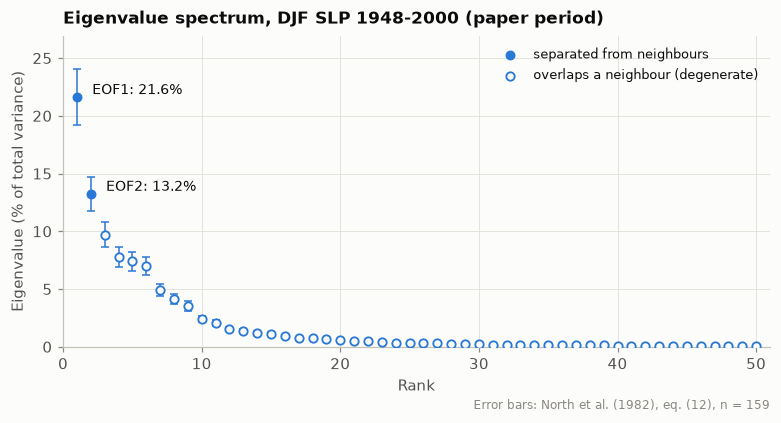

In [16]:
fig = fig_spectrum(paper, title="Eigenvalue spectrum, DJF SLP 1948-2000 (paper period)"); plt.show()

EOF1 and EOF2 stand well clear of each other and of EOF3, so both are robust modes. Further down the spectrum the error bars overlap, and those EOFs are degenerate (hollow markers).

### Figure 2: the two leading EOFs (regression maps, hPa per s.d. of the PC)

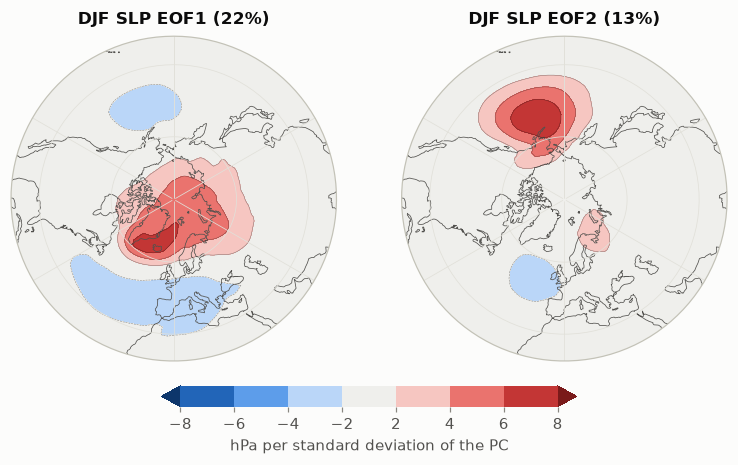

In [17]:
fig = fig_eof_maps(paper); plt.show()

EOF1 is the **Arctic Oscillation**. It has one centre over the Arctic and centres of the opposite sign over the North Atlantic and Mediterranean and over the North Pacific. EOF2 has separate North Pacific and North East Atlantic centres. Both match the paper's description.

### Figure 3: the leading principal components

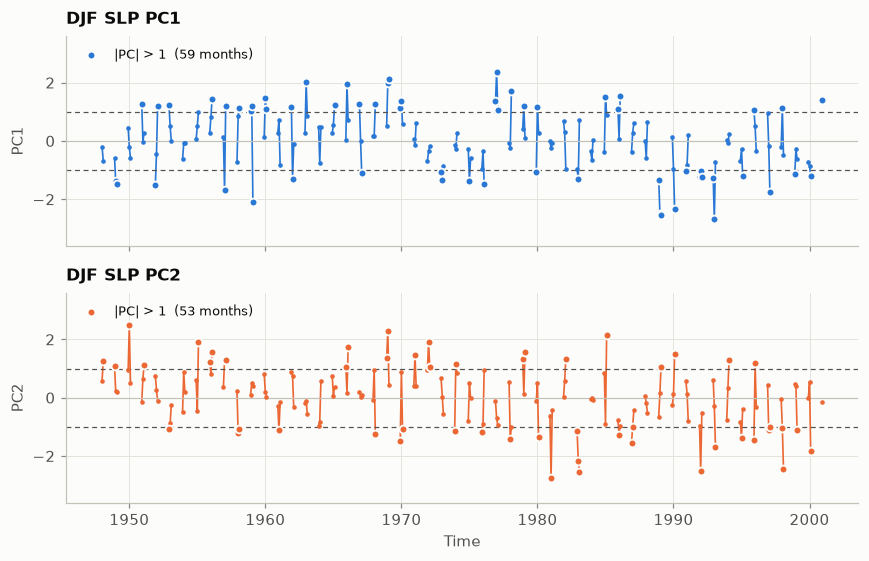

In [18]:
fig = fig_pcs(paper); plt.show()

## 7. Run B: the project window (last 30 complete winters)

The same analysis on the 90 DJF months from December 1996 to February 2026. With $n = 90$, the North error bars are wider ($\sqrt{2/90}$ against $\sqrt{2/159}$).

In [19]:
res = run_eof_analysis("slp", REGION, "DJF", n_years=30)
orient_ao(res, 0, convention="paper")
ys, ye = res.meta["year_start"], res.meta["year_end"]
print(f"winters {ys-1}/{str(ys)[2:]} to {ye-1}/{str(ye)[2:]}: n = {res.n} months "
      f"({res.time[0]:%b %Y} to {res.time[-1]:%b %Y}), p = {res.p_used} used")
res.table().head(10)

winters 1996/97 to 2025/26: n = 90 months (Dec 1996 to Feb 2026), p = 4032 used


,EOF,eigenvalue,variance_%,cumulative_%,north_error_%,separable
0,1,9998.044,24.110,24.110,3.594,True
1,2,5663.128,13.657,37.767,2.036,True
2,3,3976.528,9.589,47.356,1.430,False
3,4,3213.952,7.750,55.107,1.155,False
4,5,3100.315,7.476,62.583,1.115,False
5,6,2575.244,6.210,68.794,0.926,False
6,7,1989.203,4.797,73.591,0.715,False
7,8,1433.408,3.457,77.047,0.515,False
8,9,1297.120,3.128,80.175,0.466,False
9,10,1054.315,2.542,82.718,0.379,False


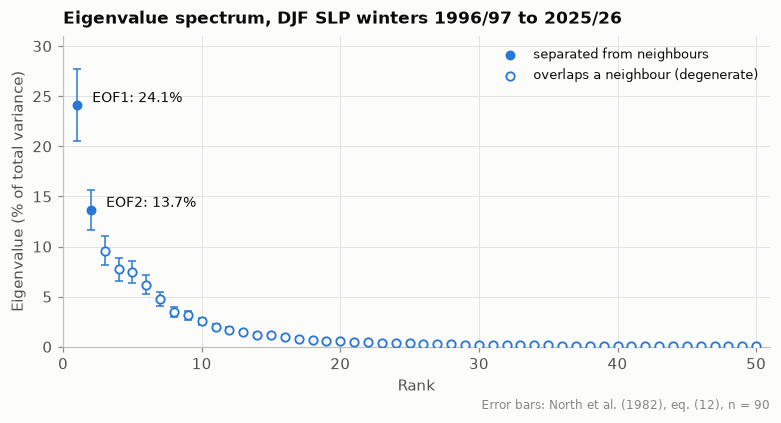

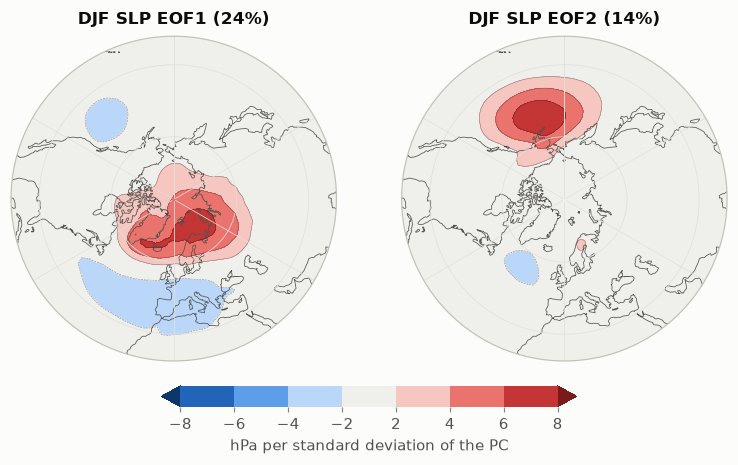

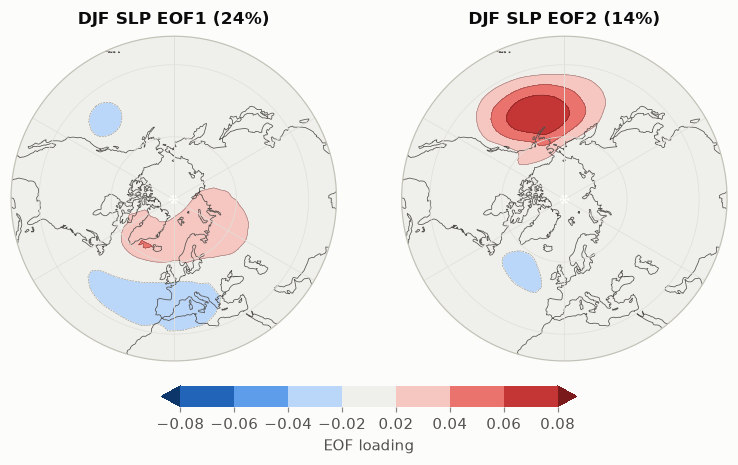

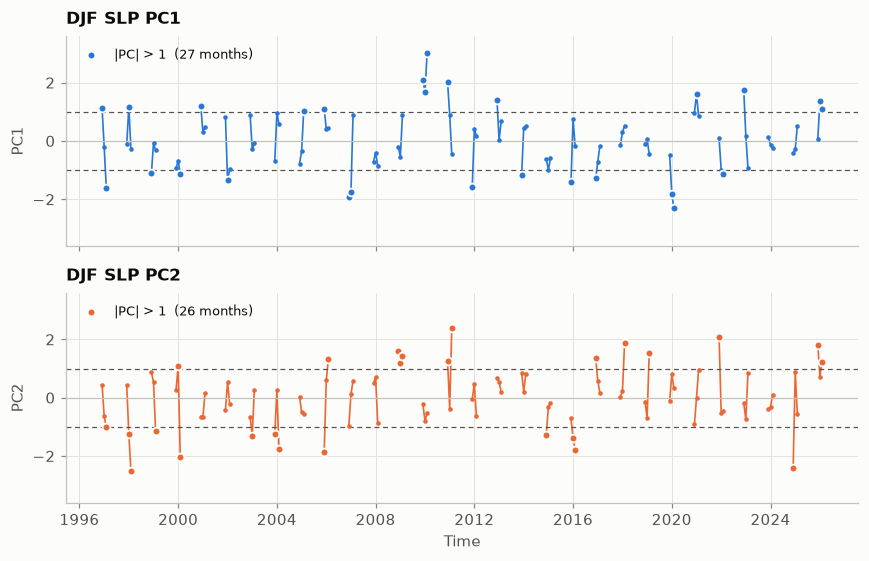

In [20]:
fig = fig_spectrum(res, title=f"Eigenvalue spectrum, DJF SLP winters {ys-1}/{str(ys)[2:]} to {ye-1}/{str(ye)[2:]}"); plt.show()
fig = fig_eof_maps(res); plt.show()
fig = fig_eof_maps(res, kind="loading"); plt.show()
fig = fig_pcs(res); plt.show()

### Validation: PC1 against NOAA CPC's official AO index

The CPC index is built from 1000 hPa heights over 20–90°N, so a correlation of $|r|$ near 1 confirms that our EOF1 is the AO. The sign is negative only because the paper's convention puts high pressure over the pole.

Run A: corr(PC1, CPC AO) = -0.984 over 153 months
Run B: corr(PC1, CPC AO) = -0.964 over 90 months


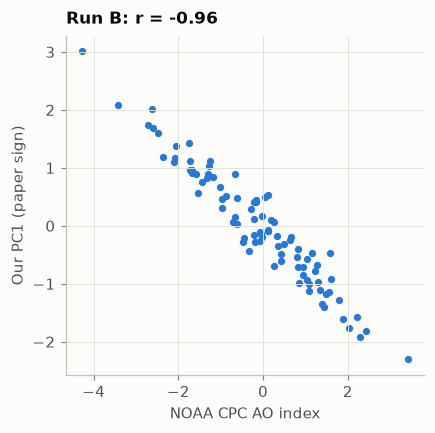

In [21]:
cpc = load_cpc_ao()

def corr_with_cpc(r):
    if cpc is None:
        return np.nan, 0
    both = pd.concat([pd.Series(r.pcs_std[:, 0], index=r.time), cpc], axis=1, join="inner").dropna()
    return float(np.corrcoef(both.iloc[:, 0], both.iloc[:, 1])[0, 1]), len(both)

ra, na = corr_with_cpc(paper)
rb, nb = corr_with_cpc(res)
print(f"Run A: corr(PC1, CPC AO) = {ra:+.3f} over {na} months")
print(f"Run B: corr(PC1, CPC AO) = {rb:+.3f} over {nb} months")

if cpc is not None:
    both = pd.concat([pd.Series(res.pcs_std[:, 0], index=res.time, name="PC1"), cpc], axis=1, join="inner")
    fig, ax = plt.subplots(figsize=(4.2, 4))
    ax.scatter(both["CPC AO"], both["PC1"], s=14, color=BLUE)
    ax.set_xlabel("NOAA CPC AO index"); ax.set_ylabel("Our PC1 (paper sign)")
    ax.set_title(f"Run B: r = {rb:+.2f}"); plt.show()

## 8. Which weighting did the paper really use?

Eq. (5) as printed multiplies the data by $\cos\phi$. The table compares that with $\sqrt{\cos\phi}$, which weights the covariance by cell area, and with no weighting at all.

In [22]:
rows = []
for w, desc in [("cos", "data x cos(lat), eq. (5) as printed"),
                ("sqrtcos", "data x sqrt(cos(lat)), covariance area-weighted"),
                ("none", "no weighting")]:
    a = run_eof_analysis("slp", REGION, "DJF", time_range=("1948-01", "2000-12"), weighting=w)
    b = run_eof_analysis("slp", REGION, "DJF", n_years=30, weighting=w)
    rows.append(dict(weighting=w, description=desc,
                     paper_period_eof1=a.var_pct[0], paper_period_eof2=a.var_pct[1],
                     project_window_eof1=b.var_pct[0], project_window_eof2=b.var_pct[1]))
    if w == "none":
        unweighted = b
rows.append(dict(weighting="paper", description="values quoted in Hannachi (2004)",
                 paper_period_eof1=21.0, paper_period_eof2=13.0,
                 project_window_eof1=np.nan, project_window_eof2=np.nan))
pd.DataFrame(rows).round(1)

,weighting,description,paper_period_eof1,paper_period_eof2,project_window_eof1,project_window_eof2
0,cos,"data x cos(lat), eq. (5) as printed",18.8,14.9,20.4,16.1
1,sqrtcos,"data x sqrt(cos(lat)), covariance area-weighted",21.6,13.2,24.1,13.7
2,none,no weighting,35.9,10.1,36.9,11.6
3,paper,values quoted in Hannachi (2004),21.0,13.0,NaN,NaN


Only $\sqrt{\cos\phi}$ reproduces the paper's 21% and 13%. Without weighting, EOF1 is inflated to about 36% because the many small polar cells are over-counted. The loadings then pile up near the pole, which is the artefact §2.2 warns about:

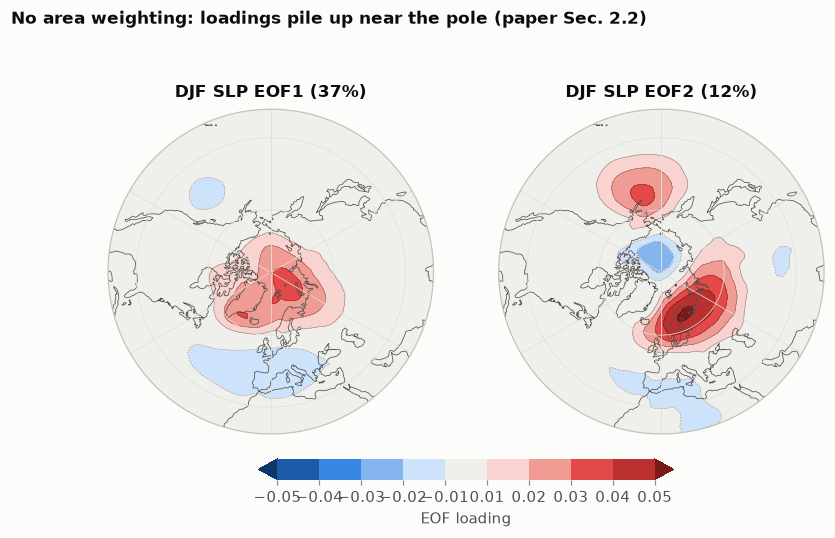

In [23]:
fig = fig_eof_maps(unweighted, kind="loading")
fig.suptitle("No area weighting: loadings pile up near the pole (paper Sec. 2.2)",
             x=0.02, ha="left", fontsize=11, fontweight="bold"); plt.show()

## 9. Section 3.4, equation (11): truncation and reconstruction

Keeping only the leading $k$ EOFs gives the best rank-$k$ approximation of the data (Eckart–Young):

$$X' \approx \sum_{j=1}^{k} c_j a_j^T. \tag{11}$$

Below is the RMSE against $k$ for Run B, and one month rebuilt from 1, 5 and 20 EOFs.

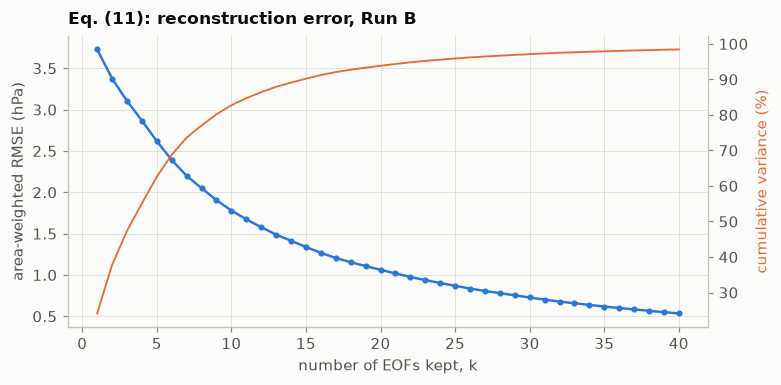

k =  1:  24.1% variance, RMSE 3.73 hPa, storage compressed  88.0x
k =  5:  62.6% variance, RMSE 2.62 hPa, storage compressed  17.6x
k = 10:  82.7% variance, RMSE 1.78 hPa, storage compressed   8.8x
k = 20:  93.8% variance, RMSE 1.06 hPa, storage compressed   4.4x


In [24]:
ks = np.arange(1, 41)
rmse = res.rmse_curve(ks)
cum = np.cumsum(res.all_var_pct)[: ks.size]

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(ks, rmse, color=BLUE, marker="o", ms=3)
ax.set_xlabel("number of EOFs kept, k"); ax.set_ylabel("area-weighted RMSE (hPa)")
ax.set_title("Eq. (11): reconstruction error, Run B")
ax2 = ax.twinx(); ax2.plot(ks, cum, color=ORANGE, lw=1.2); ax2.set_ylabel("cumulative variance (%)", color=ORANGE)
ax2.grid(False); ax2.spines["right"].set_visible(True)
fig.tight_layout(); plt.show()

for k in (1, 5, 10, 20):
    print(f"k = {k:2d}: {cum[k-1]:5.1f}% variance, RMSE {rmse[k-1]:.2f} hPa, "
          f"storage compressed {res.compression_ratio(k):5.1f}x")

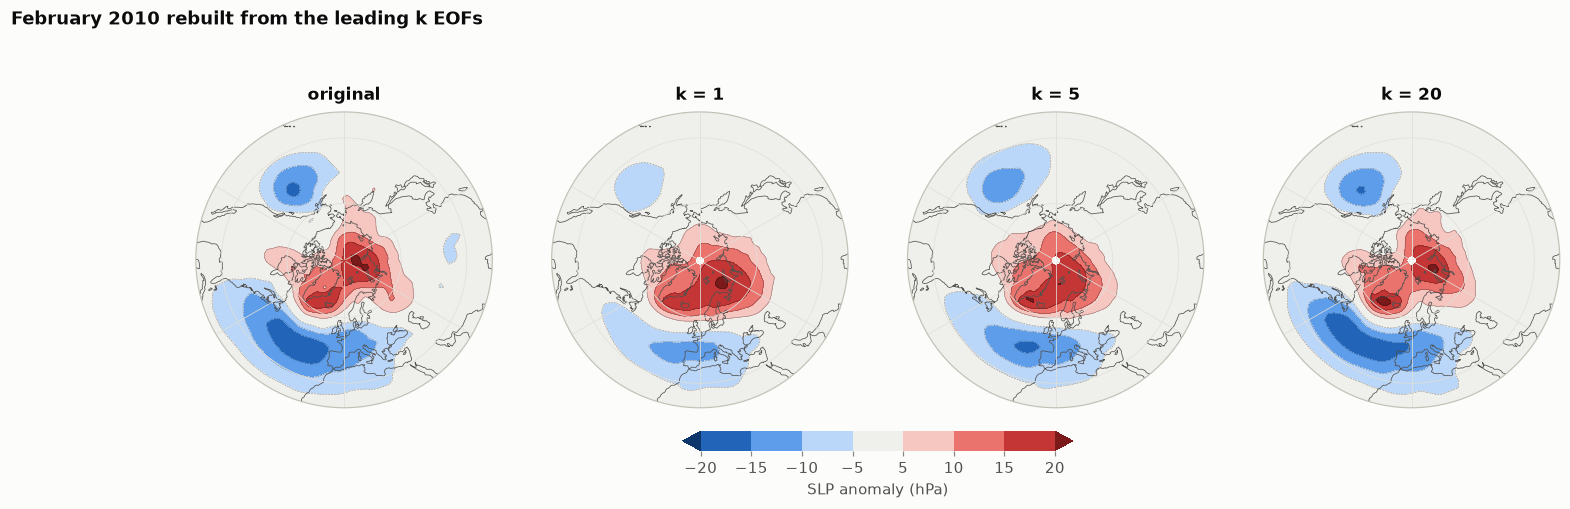

In [25]:
t = int(np.argmax(np.abs(res.pcs_std[:, 0])))       # the month with the strongest AO
panels = [("original", res.anom[t])] + [(f"k = {k}", res.reconstruct(k, t)) for k in (1, 5, 20)]
levels = _sym_levels(np.stack([p[1] for p in panels]), n=12)
fig = plt.figure(figsize=(16, 4.6))
axs = [fig.add_subplot(1, 4, i + 1, projection=ccrs.NorthPolarStereo()) for i in range(4)]
for ax, (name, f) in zip(axs, panels):
    cf = polar_map(ax, f, res.lat, res.lon, levels)
    ax.set_title(name, loc="center")
cb = fig.colorbar(cf, ax=axs, orientation="horizontal", fraction=0.05, pad=0.06, shrink=0.5)
cb.set_label("SLP anomaly (hPa)"); cb.outline.set_visible(False)
fig.suptitle(f"{res.time[t]:%B %Y} rebuilt from the leading k EOFs", x=0.02, ha="left",
             fontsize=12, fontweight="bold"); plt.show()

## 10. Numerical checks of the Section 3 properties

These are the checks from `scripts/verify_math.py`. Each one tests a property the paper derives, run on Run B.

In [26]:
results = []
def check(name, ok, detail):
    results.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

U, s, Vt = res._svd
vmask = res.valid.reshape(-1)
w = res.weights.reshape(-1)[vmask]
Xw = res.anom.reshape(res.n, -1)[:, vmask] * w

m = np.abs(res.anom.reshape(res.n, -1)[:, vmask].mean(axis=0)).max()
check("anomalies are centred (eq. 4)", m < 1e-8, f"max |column mean| = {m:.1e} hPa")

G = Vt[:20] @ Vt[:20].T
e = np.abs(G - np.eye(20)).max()
check("EOFs orthonormal (a_i . a_j = delta_ij)", e < 1e-10, f"max error = {e:.1e}")

C = np.corrcoef(res.pcs.T)
e = np.abs(C - np.eye(C.shape[0])).max()
check("PCs uncorrelated", e < 1e-8, f"max |off-diagonal corr| = {e:.1e}")

lam_eig = np.sort(np.linalg.eigvalsh(Xw @ Xw.T / (res.n - 1)))[::-1][:20]
e = np.abs(lam_eig - res.all_var_pct[:20] * res.total_var / 100).max() / lam_eig[0]
check("SVD eigenvalues = eigenvalues of Sigma (eq. 9, 13)", e < 1e-10, f"max relative error = {e:.1e}")

a1 = Vt[0]
Sa = Xw.T @ (Xw @ a1) / (res.n - 1)
e = np.linalg.norm(Sa - res.eigvals[0] * a1) / res.eigvals[0]
check("Sigma a_1 = lambda_1 a_1 (eq. 9)", e < 1e-10, f"relative residual = {e:.1e}")

e = np.abs(Xw @ Vt[0] - res.pcs[:, 0]).max() / np.abs(res.pcs[:, 0]).max()
check("PC_1 = X'_w a_1 (eq. 10)", e < 1e-10, f"max relative error = {e:.1e}")

full = res.reconstruct(res.all_var_pct.size)
e = np.nanmax(np.abs(full - res.anom)[:, res.valid])
check("full expansion reconstructs X' exactly (eq. 11)", e < 1e-8, f"max error = {e:.1e} hPa")

check("explained variances sum to 100%", abs(res.all_var_pct.sum() - 100) < 1e-9,
      f"sum = {res.all_var_pct.sum():.12f}")

k = 5
err = np.sum((Xw - (U[:, :k] * s[:k]) @ Vt[:k]) ** 2)
tail = np.sum(s[k:] ** 2)
check("rank-5 error = sum of discarded sigma^2 (Eckart-Young)", abs(err - tail) / tail < 1e-10,
      f"{err:.6e} vs {tail:.6e}")

ok = abs(paper.var_pct[0] - 21) < 1 and abs(paper.var_pct[1] - 13) < 1
check("paper's 21% / 13% reproduced (1948-2000)", ok, f"{paper.var_pct[0]:.1f}% / {paper.var_pct[1]:.1f}%")

checks = pd.DataFrame(results)
print(f"{(checks.result == 'PASS').sum()} of {len(checks)} checks passed")
checks

10 of 10 checks passed


,check,result,detail
0,anomalies are centred (eq. 4),PASS,max |column mean| = 1.0e-13 hPa
1,EOFs orthonormal (a_i . a_j = delta_ij),PASS,max error = 1.8e-15
2,PCs uncorrelated,PASS,max |off-diagonal corr| = 1.1e-15
3,"SVD eigenvalues = eigenvalues of Sigma (eq. 9,...",PASS,max relative error = 1.5e-15
4,Sigma a_1 = lambda_1 a_1 (eq. 9),PASS,relative residual = 2.0e-15
5,PC_1 = X'_w a_1 (eq. 10),PASS,max relative error = 1.2e-15
6,full expansion reconstructs X' exactly (eq. 11),PASS,max error = 2.8e-13 hPa
7,explained variances sum to 100%,PASS,sum = 100.000000000000
8,rank-5 error = sum of discarded sigma^2 (Eckar...,PASS,1.380914e+06 vs 1.380914e+06
9,paper's 21% / 13% reproduced (1948-2000),PASS,21.6% / 13.2%


## 11. Summary

In [27]:
summary = pd.DataFrame([
    dict(run="Hannachi (2004)", months=np.nan, period="1948-2000", eof1_pct=21.0, eof2_pct=13.0,
         eof1_err=np.nan, eof2_err=np.nan, corr_pc1_cpc_ao=np.nan),
    dict(run="Run A, paper period", months=paper.n, period=f"{paper.time[0]:%Y-%m} to {paper.time[-1]:%Y-%m}",
         eof1_pct=paper.var_pct[0], eof2_pct=paper.var_pct[1], eof1_err=paper.north_err_pct[0],
         eof2_err=paper.north_err_pct[1], corr_pc1_cpc_ao=ra),
    dict(run="Run B, last 30 winters", months=res.n, period=f"{res.time[0]:%Y-%m} to {res.time[-1]:%Y-%m}",
         eof1_pct=res.var_pct[0], eof2_pct=res.var_pct[1], eof1_err=res.north_err_pct[0],
         eof2_err=res.north_err_pct[1], corr_pc1_cpc_ao=rb),
])
summary.round(2)

,run,months,period,eof1_pct,eof2_pct,eof1_err,eof2_err,corr_pc1_cpc_ao
0,Hannachi (2004),NaN,1948-2000,21.00,13.00,NaN,NaN,NaN
1,"Run A, paper period",159.0,1948-01 to 2000-12,21.62,13.25,2.42,1.49,-0.98
2,"Run B, last 30 winters",90.0,1996-12 to 2026-02,24.11,13.66,3.59,2.04,-0.96


- **The paper is reproduced.** On the paper's own sample, EOF1 and EOF2 explain about 21.6% and 13.2% of the variance, against the quoted 21% and 13%. The two are separable by North's rule, and PC1 correlates with NOAA's AO index at |r| ≈ 0.98.
- **The weighting matters.** The paper's numbers come from $\sqrt{\cos\phi}$ weighting of the data, which is area weighting of the covariance, not the literal $\cos\phi$ of eq. (5).
- **The last 30 winters** give the same two modes. EOF1 explains slightly more variance, with wider error bars because $n$ is smaller.
- **All the Section 3 properties hold to machine precision**: orthonormal EOFs, uncorrelated PCs, SVD = eigen-decomposition, exact full reconstruction, and the Eckart–Young truncation error.